# What held-out diagnostics can establish

This native Julia companion preserves the public observations, chronological boundary, model architecture, objectives, fixed training schedule and diagnostic definitions. Julia TimeGAN initialization, training and sampling use local `MersenneTwister` streams with the displayed integer seeds; other demonstrations use `Xoshiro`. Their realizations differ from NumPy and PyTorch. The diagnostic logistic solver uses tighter convergence for the same fixed objective. Native arrays, model weights and training draws are saved as CSV/TOML under `outputs/julia/artifacts` for independent verification. Run these three notebooks in order. Figures use the requested dark theme.

A lag-one correlation for feature $j$ compares adjacent values across the held-out windows:

$$
\widehat\rho_j=
\frac{\sum_k(x_{k,j}-\bar x_j)(y_{k,j}-\bar y_j)}
{\left[\sum_k(x_{k,j}-\bar x_j)^2\sum_k(y_{k,j}-\bar y_j)^2\right]^{1/2}}.
$$

Here, $x_{k,j}$ is a feature value at one position; $y_{k,j}$ is the next value in the same window; $k$ indexes all adjacent pairs; $\bar x_j$ and $\bar y_j$ are their means. The absolute difference between real and generated correlations measures one narrow aspect of temporal dependence.

For next-step prediction, the squared error is

$$
\operatorname{MSE}=\frac{1}{Nd}\sum_{i=1}^{N}\sum_{j=1}^{d}(Y_{i,j}-\widehat Y_{i,j})^2.
$$

Here, $N$ is the number of held-out windows; $d$ is the feature count; $Y_{i,j}$ is the last value of feature $j$ in held-out window $i$; $\widehat Y_{i,j}$ is its prediction from the preceding values. One predictor is fitted to generated windows and another to observed training windows.

The classifier for observed and generated windows is summarized by balanced accuracy:

$$
\operatorname{BA}=\frac{1}{2}\left(\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}}+\frac{\mathrm{TN}}{\mathrm{TN}+\mathrm{FP}}\right).
$$

Here, $\mathrm{TP}$ and $\mathrm{TN}$ are correctly classified real and generated windows; $\mathrm{FN}$ and $\mathrm{FP}$ are the corresponding errors. A value near one half indicates weak separation by this particular classifier, not proof that the two distributions are equal.

## Fresh Generated Windows

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("03_generative_financial_time_series");
using CSV, TOML
artifacts = joinpath(book_root(), "outputs", "julia", "artifacts", "03_generative_financial_time_series")
mkpath(artifacts)

function save_tensor(name, values)
    CSV.write(joinpath(artifacts, name*".csv"), DataFrame(Value=vec(values)))
    open(joinpath(artifacts, name*".toml"), "w") do stream
        TOML.print(stream, Dict("shape"=>collect(size(values)), "storage_order"=>"column-major"))
    end
    return nothing
end

function load_tensor(name)
    shape = TOML.parsefile(joinpath(artifacts, name*".toml"))["shape"]
    values = CSV.read(joinpath(artifacts, name*".csv"), DataFrame).Value
    return reshape(Float64.(values), Tuple(shape))
end

pack_parameters(values::NamedTuple) = Dict(string(key)=>pack_parameters(getproperty(values, key)) for key in keys(values))
pack_parameters(values::AbstractArray) = Dict("shape"=>collect(size(values)), "values"=>vec(values))

function unpack_parameters(template::NamedTuple, saved)
    return NamedTuple{keys(template)}(Tuple(unpack_parameters(getproperty(template, key), saved[string(key)]) for key in keys(template)))
end

function unpack_parameters(template::AbstractArray, saved)
    @assert Tuple(saved["shape"]) == size(template)
    return reshape(Float64.(saved["values"]), size(template))
end

function save_parameters(name, parameters)
    open(joinpath(artifacts, name*".toml"), "w") do stream
        TOML.print(stream, pack_parameters(parameters))
    end
    return nothing
end
prepared_metadata = TOML.parsefile(joinpath(artifacts, "prepared_metadata.toml"))
training_windows = load_tensor("training_windows")
validation_windows = load_tensor("validation_windows")
minimum_values = prepared_metadata["minimum"]
scale = prepared_metadata["scale"]
feature_names = prepared_metadata["feature_names"]
window_length = prepared_metadata["window_length"]
@assert size(training_windows) == (6409, 20, 2)
training_scaled,validation_scaled = training_windows,validation_windows
model = RiskLabAI.Data.TimeGAN(2,8;seed=4104)
model.parameters = unpack_parameters(model.parameters,TOML.parsefile(joinpath(artifacts,"timegan_parameters.toml")))
real_training = training_scaled.*reshape(scale,1,1,:).+reshape(minimum_values,1,1,:)
real_validation = validation_scaled.*reshape(scale,1,1,:).+reshape(minimum_values,1,1,:)
training_noise = randn(MersenneTwister(4106),size(real_training,1),window_length,8)
validation_noise = randn(MersenneTwister(4107),size(real_validation,1),window_length,8)
synthetic_training_scaled = RiskLabAI.Data.sample_timegan(model,size(real_training,1),window_length;seed=4106,normal_draws=training_noise)
synthetic_validation_scaled = RiskLabAI.Data.sample_timegan(model,size(real_validation,1),window_length;seed=4107,normal_draws=validation_noise)
synthetic_training = synthetic_training_scaled.*reshape(scale,1,1,:).+reshape(minimum_values,1,1,:)
synthetic_validation = synthetic_validation_scaled.*reshape(scale,1,1,:).+reshape(minimum_values,1,1,:)
@assert size(synthetic_training) == size(real_training)
@assert size(synthetic_validation) == size(real_validation)
@assert all(isfinite,synthetic_training)
@assert all(isfinite,synthetic_validation)
save_tensor("synthetic_training",synthetic_training)
save_tensor("synthetic_validation",synthetic_validation)
save_tensor("sample_validation_noise",validation_noise)


In [2]:
quality = RiskLabAI.Data.timegan_quality_report(real_training,real_validation,synthetic_training,synthetic_validation)
shuffle_generator = Xoshiro(4110)
shuffled_training,shuffled_validation = copy(real_training),copy(real_validation)
training_permutations = hcat([randperm(shuffle_generator,window_length) for _ in axes(shuffled_training,1)]...)'
validation_permutations = hcat([randperm(shuffle_generator,window_length) for _ in axes(shuffled_validation,1)]...)'
for index in axes(shuffled_training,1)
    shuffled_training[index,:,:] = real_training[index,training_permutations[index,:],:]
end
for index in axes(shuffled_validation,1)
    shuffled_validation[index,:,:] = real_validation[index,validation_permutations[index,:],:]
end
shuffled_quality = RiskLabAI.Data.timegan_quality_report(real_training,real_validation,shuffled_training,shuffled_validation)
CSV.write(joinpath(artifacts,"training_permutations.csv"),DataFrame(training_permutations,:auto))
CSV.write(joinpath(artifacts,"validation_permutations.csv"),DataFrame(validation_permutations,:auto))
lag_table = DataFrame("Feature"=>feature_names,"Observed held-out correlation"=>quality.real_lag_one_correlation,"Generated correlation"=>quality.synthetic_lag_one_correlation,"Generated absolute gap"=>quality.lag_one_absolute_gap,"Time-shuffled correlation"=>shuffled_quality.synthetic_lag_one_correlation,"Time-shuffled absolute gap"=>shuffled_quality.lag_one_absolute_gap)
save_data(lag_table,paths,"lag_correlation_comparison")
save_table(lag_table,paths,"lag_correlation_diagnostics";caption="Lag-one correlations and absolute gaps on the held-out period.",label="tab:chapter4-lag-diagnostics")
scalar_quality = DataFrame("Diagnostic"=>["Next-step error after fitting generated windows","Next-step error after fitting observed windows","Balanced accuracy for observed and generated windows"],"Generated windows"=>[quality.synthetic_trained_prediction_mse,quality.real_trained_prediction_mse,quality.balanced_discriminator_accuracy],"Time-shuffled windows"=>[shuffled_quality.synthetic_trained_prediction_mse,shuffled_quality.real_trained_prediction_mse,shuffled_quality.balanced_discriminator_accuracy])
save_data(scalar_quality,paths,"scalar_quality_comparison")
save_table(scalar_quality,paths,"held_out_quality";caption="Held-out predictive and discrimination diagnostics.",label="tab:chapter4-held-out-quality")


Row,Feature,Observed held-out correlation,Generated correlation,Generated absolute gap,Time-shuffled correlation,Time-shuffled absolute gap
,String,Float64,Float64,Float64,Float64,Float64
1,Daily log return (%),-0.145809,0.5652,0.711009,-0.0118552,0.133954
2,Twenty-day return volatility (%),0.990743,0.998608,0.00786488,0.859238,0.131505


Row,Diagnostic,Generated windows,Time-shuffled windows
,String,Float64,Float64
1,Next-step error after fitting generated windows,2.81657,1.33093
2,Next-step error after fitting observed windows,1.26255,1.26255
3,Balanced accuracy for observed and generated windows,0.998426,0.501574


In [3]:
moment_rows,distribution_rows = NamedTuple[],NamedTuple[]
sources = [("Observed held-out",real_validation),("Generated",synthetic_validation),("Time-shuffled",shuffled_validation)]
for (source,windows) in sources, (j,feature) in enumerate(feature_names)
    values = vec(permutedims(windows[:,:,j]))
    push!(moment_rows,(;source,feature,average=mean(values),deviation=std(values),lower=quantile(values,.05),median=median(values),upper=quantile(values,.95)))
    selected = length(values)>12000 ? values[floor.(Int,range(0,length(values)-1;length=12000)).+1] : values
    append!(distribution_rows,[(;source,feature,value) for value in selected])
end
moment_table,distribution_values = DataFrame(moment_rows),DataFrame(distribution_rows)
rename!(moment_table,["Source","Feature","Mean","Standard deviation","5th percentile","Median","95th percentile"])
rename!(distribution_values,["Source","Feature","Value"])
save_data(distribution_values,paths,"distribution_values")
save_table(moment_table,paths,"distribution_summary";caption="Held-out feature summaries for observed, generated, and time-shuffled windows.",label="tab:chapter4-distribution-summary")
selected_indices = [1,401,801,1201]
selected_rows = NamedTuple[]
for (source,windows) in [("Observed held-out",real_validation),("Generated",synthetic_validation)], (window,index) in enumerate(selected_indices), day in 1:window_length, (j,feature) in enumerate(feature_names)
    push!(selected_rows,(;source,window,day,feature,value=windows[index,day,j]))
end
selected_windows = DataFrame(selected_rows)
rename!(selected_windows,["Source","Window","Relative day","Feature","Value"])
save_data(selected_windows,paths,"selected_windows");


Row,Source,Feature,Mean,Standard deviation,5th percentile,Median,95th percentile
,String,String,Float64,Float64,Float64,Float64,Float64
1,Observed held-out,Daily log return (%),0.0681164,1.56395,-2.5055,0.14331,2.25827
2,Observed held-out,Twenty-day return volatility (%),1.37643,0.766104,0.601944,1.21416,2.50635
3,Generated,Daily log return (%),-0.964014,0.047381,-1.02508,-0.969742,-0.853922
4,Generated,Twenty-day return volatility (%),2.02845,0.119783,1.95433,1.97033,2.29648
5,Time-shuffled,Daily log return (%),0.0681164,1.56395,-2.5055,0.14331,2.25827
6,Time-shuffled,Twenty-day return volatility (%),1.37643,0.766104,0.601944,1.21416,2.50635


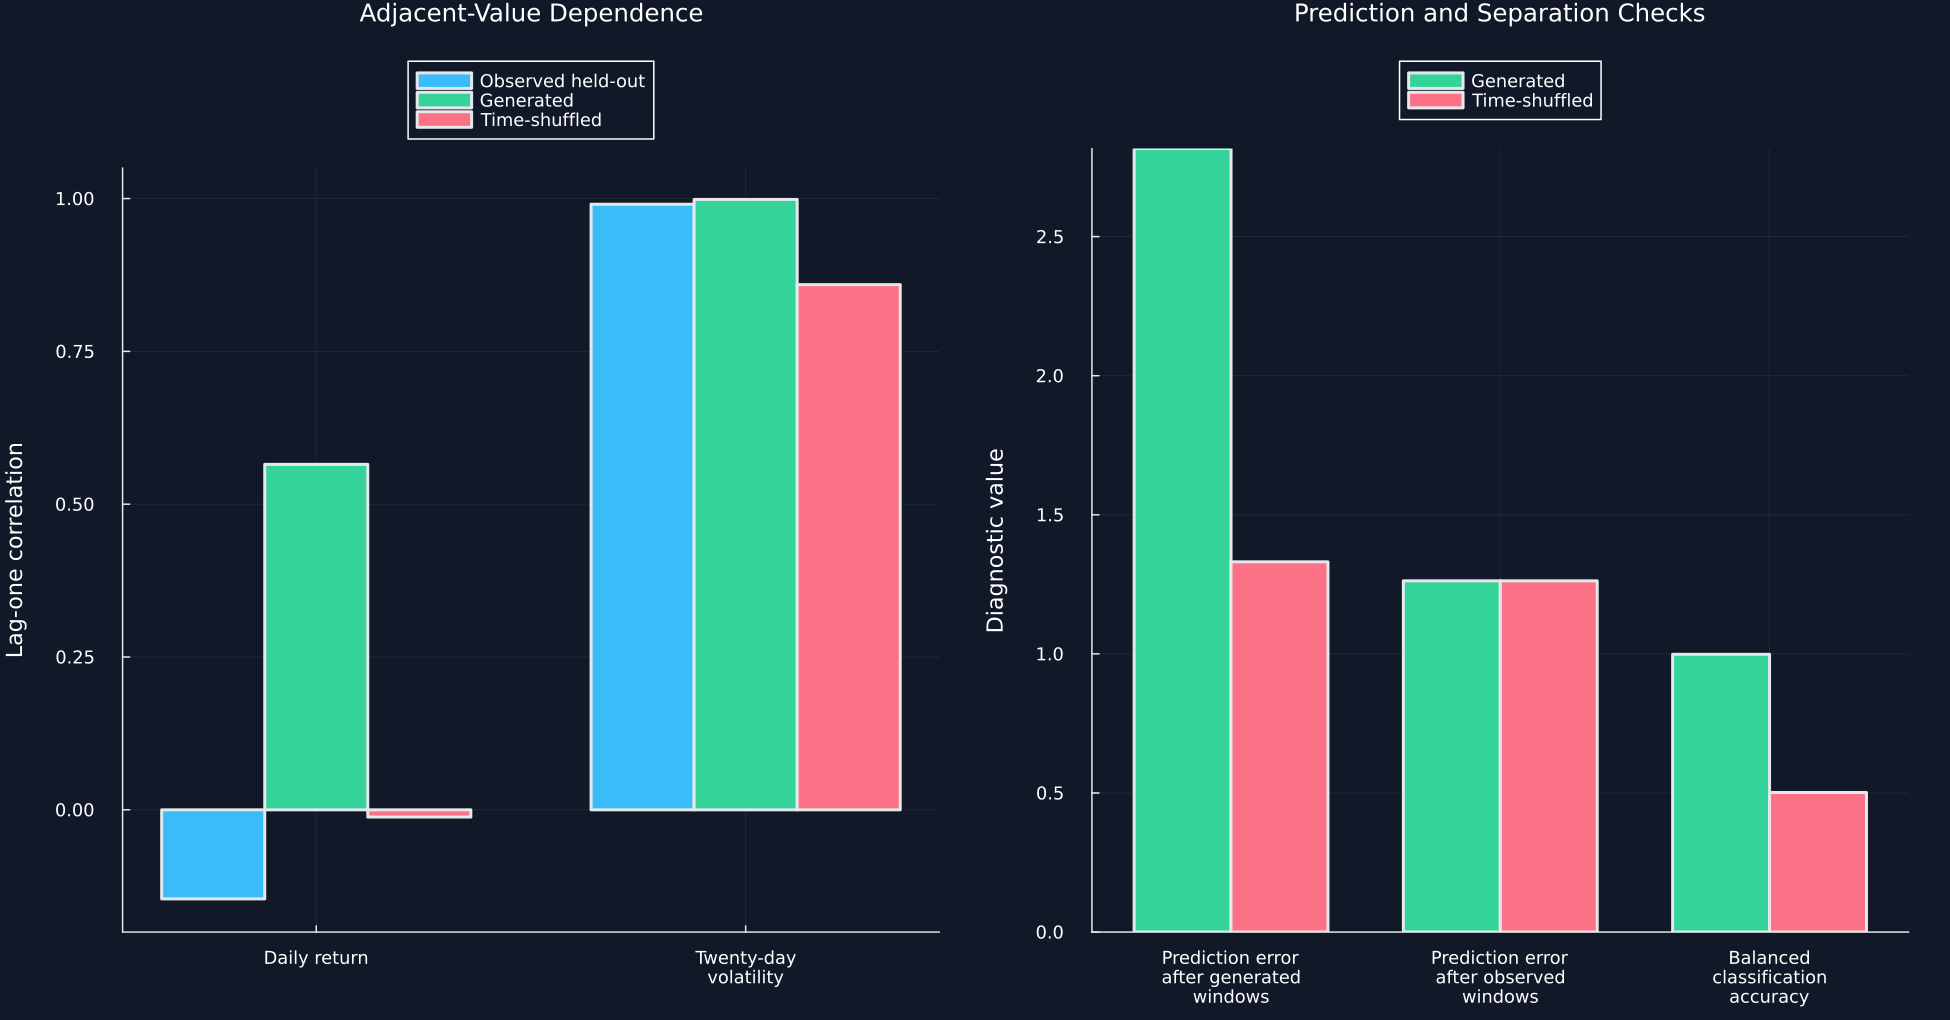

In [4]:
left = plot(;xticks=([1,2],["Daily return","Twenty-day
volatility"]),ylabel="Lag-one correlation",title="Adjacent-Value Dependence",legend=:outertop,ylims=(-.2,1.05))
for (offset,values,color,label) in [(-.24,quality.real_lag_one_correlation,palette.cyan,"Observed held-out"),(0.,quality.synthetic_lag_one_correlation,palette.green,"Generated"),(.24,shuffled_quality.synthetic_lag_one_correlation,palette.rose,"Time-shuffled")]
    bar!(left,[1,2].+offset,values;bar_width=.24,color,label)
end
labels = ["Prediction error
after generated
windows","Prediction error
after observed
windows","Balanced
classification
accuracy"]
right = plot(;xticks=(1:3,labels),ylabel="Diagnostic value",title="Prediction and Separation Checks",legend=:outertop)
bar!(right,(1:3).- .18,scalar_quality[!,"Generated windows"];bar_width=.36,color=palette.green,label="Generated")
bar!(right,(1:3).+ .18,scalar_quality[!,"Time-shuffled windows"];bar_width=.36,color=palette.rose,label="Time-shuffled")
save_figure(plot(left,right;layout=(1,2),size=(1300,680)),paths,"held_out_diagnostics")


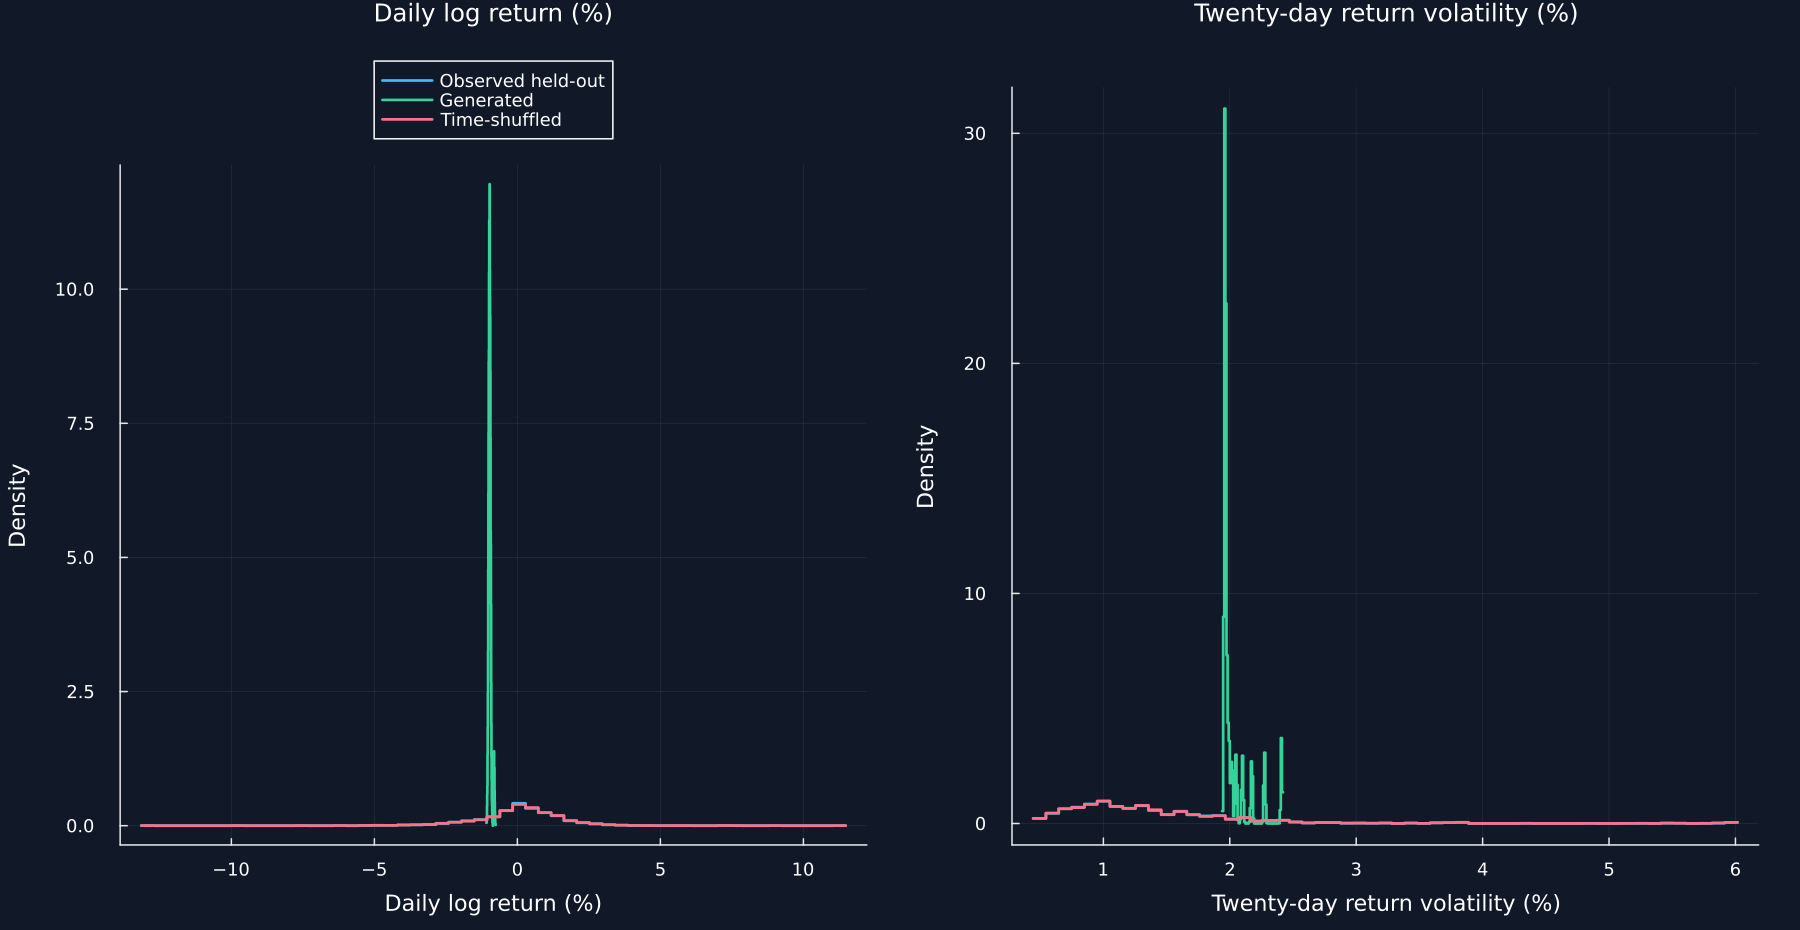

In [5]:
panels = []
for (index,feature) in enumerate(feature_names)
    panel = plot(;xlabel=feature,ylabel="Density",title=feature,legend=:outertop)
    for (source,color) in [("Observed held-out",palette.cyan),("Generated",palette.green),("Time-shuffled",palette.rose)]
        values = distribution_values[(distribution_values.Source.==source).&(distribution_values.Feature.==feature),:Value]
        edges = collect(range(minimum(values),maximum(values);length=56))
        counts = zeros(Int,55)
        for value in values
            counts[clamp(searchsortedlast(edges,value),1,55)] += 1
        end
        horizontal = repeat(edges;inner=2)[2:end-1]
        density = repeat(counts./(length(values).*diff(edges));inner=2)
        plot!(panel,horizontal,density;color,linewidth=1.8,label=index==1 ? source : false)
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1200,620)),paths,"distribution_comparison")


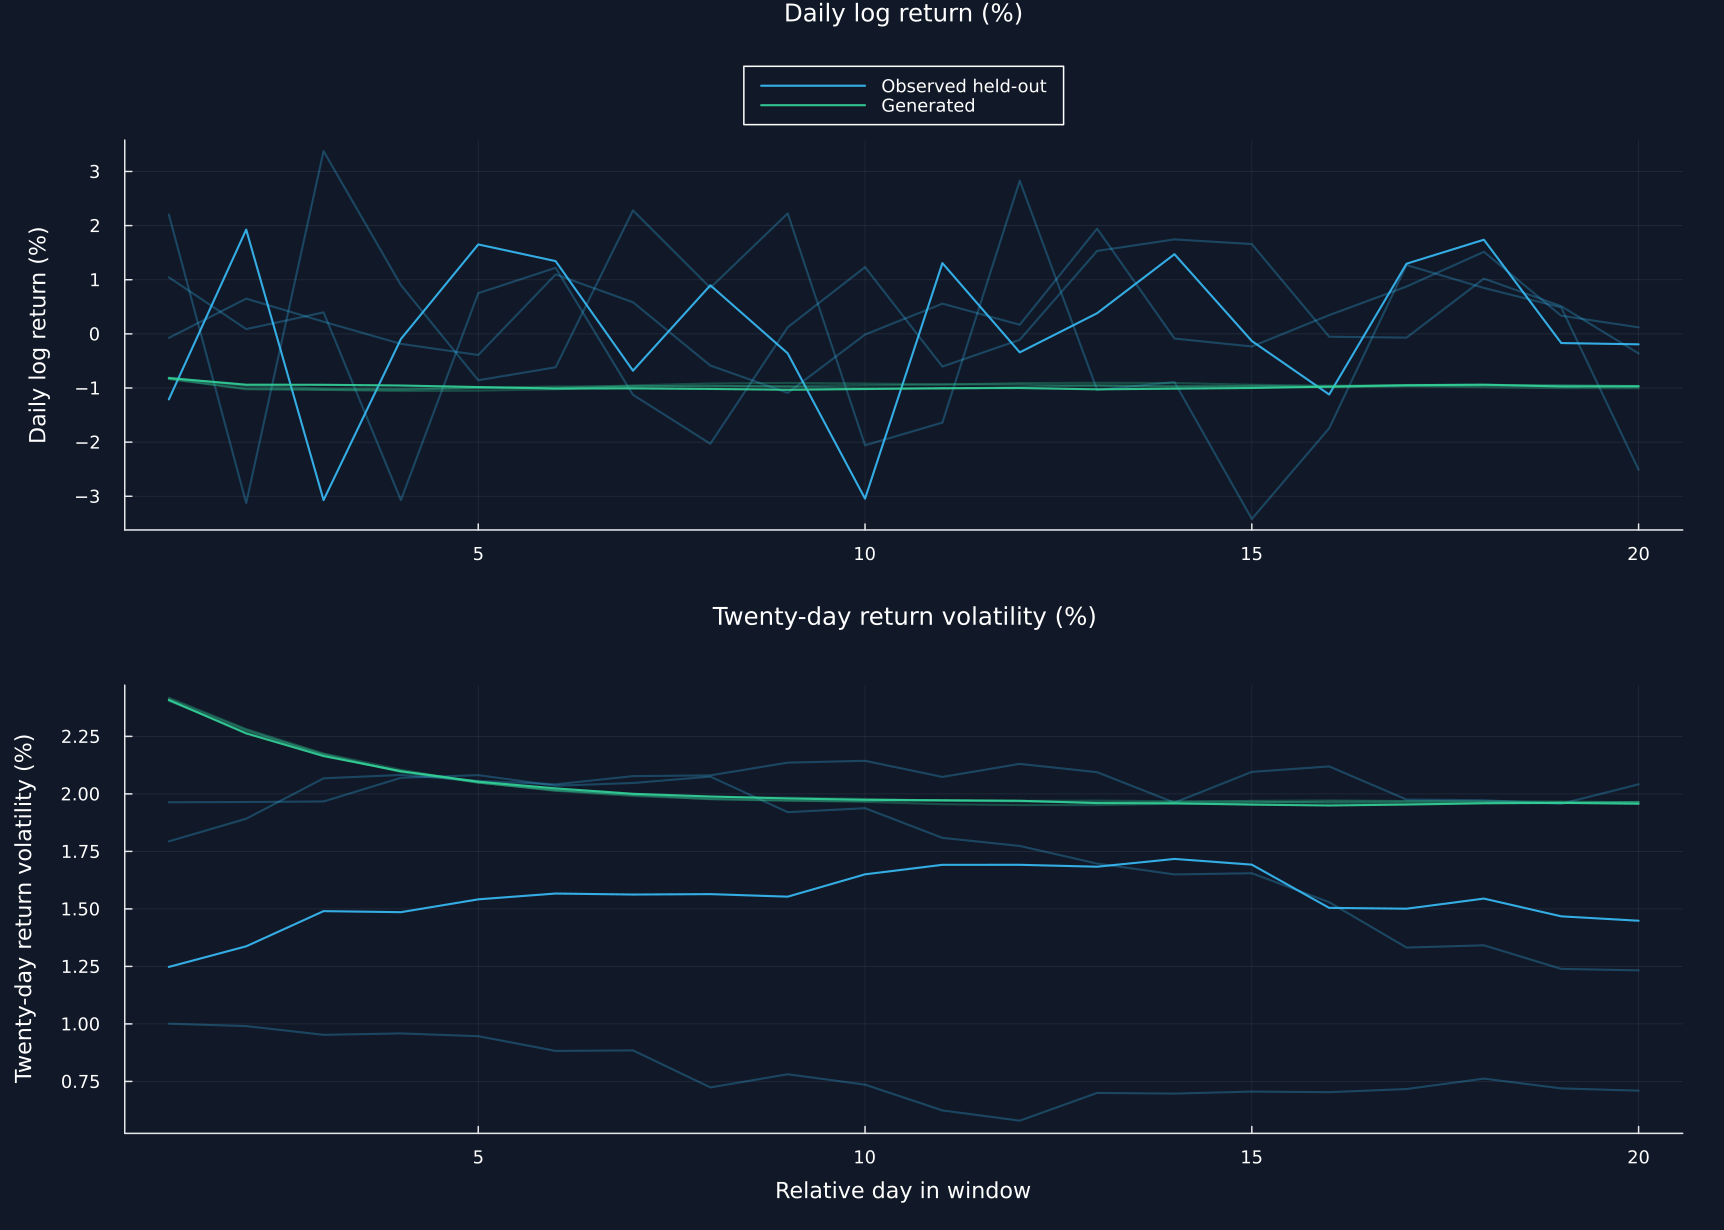

In [6]:
panels = []
for (index,feature) in enumerate(feature_names)
    panel = plot(;ylabel=feature,title=feature,xlabel=index==2 ? "Relative day in window" : "",legend=:outertop)
    for (source,color) in [("Observed held-out",palette.cyan),("Generated",palette.green)], window in 1:4
        part = selected_windows[(selected_windows.Source.==source).&(selected_windows.Window.==window).&(selected_windows.Feature.==feature),:]
        plot!(panel,part[!,"Relative day"],part.Value;color,alpha=window>1 ? .28 : .9,linewidth=1.4,label=window==1 && index==1 ? source : false)
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(2,1),size=(1150,820)),paths,"selected_real_generated_windows")


## A Deliberately Broken Comparison

A time-shuffled window preserves its observed values but changes their order:

$$
\widetilde X_{i,t}=X_{i,\pi_i(t)}.
$$

Here, $X_{i,t}$ is the value at position $t$ in window $i$; $\pi_i$ is a random permutation of the positions in that window; $\widetilde X_{i,t}$ is the reordered value. This construction leaves each window's marginal values unchanged while deliberately damaging temporal order. It checks whether the diagnostics respond to an obvious loss of sequence information.

In [7]:
known_generator = Xoshiro(891)
constant_sequences = repeat(randn(known_generator,100,1,1),1,5,1)
independent_sequences = randn(known_generator,100,5,1)
known_quality = RiskLabAI.Data.timegan_quality_report(constant_sequences[1:60,:,:],constant_sequences[61:end,:,:],independent_sequences[1:60,:,:],independent_sequences[61:end,:,:])
@assert known_quality.lag_one_absolute_gap[1] > .7
@assert known_quality.synthetic_trained_prediction_mse > known_quality.real_trained_prediction_mse+.1
save_tensor("constant_sequences",constant_sequences)
save_tensor("independent_sequences",independent_sequences)
destroyed_table = DataFrame("Diagnostic"=>["Lag-one absolute gap","Next-step error after fitting independent windows","Next-step error after fitting constant windows"],"Value"=>[known_quality.lag_one_absolute_gap[1],known_quality.synthetic_trained_prediction_mse,known_quality.real_trained_prediction_mse],"Expected relation"=>["Greater than 0.7","More than 0.1 above the error from constant windows","Reference value"])
save_data(destroyed_table,paths,"destroyed_temporal_check")
save_table(destroyed_table,paths,"destroyed_temporal_check";caption="Controlled check after temporal information is deliberately destroyed.",label="tab:chapter4-destroyed-temporal-check")
limits = DataFrame("Diagnostic"=>["Lag-one correlation","Next-step prediction error","Balanced classification accuracy","Feature summaries","Selected windows"],"What it checks"=>["One-step linear dependence","Transfer of a simple predictive relation","Separation by one fitted classifier","Marginal location and spread","Visible finite-window behavior"],"What it does not establish"=>["Long memory or nonlinear dependence","Trading value or broad forecasting skill","Equality of the full distributions","Temporal order","A coherent unlimited market history"])
save_table(limits,paths,"diagnostic_limits";caption="Interpretation limits for the reported diagnostics.",label="tab:chapter4-diagnostic-limits")


Row,Diagnostic,Value,Expected relation
,String,Float64,String
1,Lag-one absolute gap,1.06798,Greater than 0.7
2,Next-step error after fitting independent windows,1.82725,More than 0.1 above the error from constant windows
3,Next-step error after fitting constant windows,1.71194e-5,Reference value


Row,Diagnostic,What it checks,What it does not establish
,String,String,String
1,Lag-one correlation,One-step linear dependence,Long memory or nonlinear dependence
2,Next-step prediction error,Transfer of a simple predictive relation,Trading value or broad forecasting skill
3,Balanced classification accuracy,Separation by one fitted classifier,Equality of the full distributions
4,Feature summaries,Marginal location and spread,Temporal order
5,Selected windows,Visible finite-window behavior,A coherent unlimited market history


## Tests

In [8]:
@assert 0 <= quality.balanced_discriminator_accuracy <= 1
@assert quality.synthetic_trained_prediction_mse >= 0
@assert quality.real_trained_prediction_mse >= 0
@assert all(isfinite,quality.lag_one_absolute_gap)
@assert RiskLabAI.Data.sample_timegan(model,12,window_length;seed=4200) == RiskLabAI.Data.sample_timegan(model,12,window_length;seed=4200)
@assert !(RiskLabAI.Data.sample_timegan(model,12,window_length;seed=4200) ≈ RiskLabAI.Data.sample_timegan(model,12,window_length;seed=4201))
diagnostic_checks = DataFrame("Check"=>["Fresh generated training windows","Fresh generated held-out windows","Finite lag-one gaps","Nonnegative prediction errors","Balanced accuracy in unit interval","Equal seeds reproduce samples","Different seeds change samples","Destroyed temporal information detected"],"Result"=>fill("Pass",8))
save_table(diagnostic_checks,paths,"diagnostic_checks";caption="Checks for fresh samples and held-out diagnostic behavior.",label="tab:chapter4-diagnostic-checks")


Row,Check,Result
,String,String
1,Fresh generated training windows,Pass
2,Fresh generated held-out windows,Pass
3,Finite lag-one gaps,Pass
4,Nonnegative prediction errors,Pass
5,Balanced accuracy in unit interval,Pass
6,Equal seeds reproduce samples,Pass
7,Different seeds change samples,Pass
8,Destroyed temporal information detected,Pass
